<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 2 · Features</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A tabular model forecasts from a table: one row per series and forecast origin $t$, the target $y_{t+h}$, and features computed only from what was known at $t$. For a direct model of horizon $h$ with data latency $d$, the closest usable lag is $h + d$ steps before the target. Seasonal lags, windows, differences and ratios all come from that known series: shifted first, then rolled, within each series. On a synthetic four-farm panel of weekly harvest, the leakage module's hide-the-future test passes every honest feature and catches a window rolled before shifting and a lag shifted without `groupby`. Across 20 simulated panels, seasonal lags and trailing windows take a ridge regression from far behind seasonal naive to $1 - 0.92 = 8\%$ below its error. Afterwards you should be able to build lag and window features for a panel, test each for leakage, and decide how many to keep by ablation.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import acf, pacf

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110

## From a series to a table

A tabular model needs rows. For a **direct** model, fitted for one horizon $h$, each row is one series at one forecast origin $t$: the target is $y_{t+h}$, and the features are whatever could be computed from the data as they stood at $t$, the as-of rule from [Leakage](../leakage/leakage.ipynb). With data latency $d$ the newest known value is $y_{t-d}$, so, as [Horizon, frequency and target](../horizon-frequency-and-target.qmd) showed, the shortest usable lag counted back from the target time $t+h$ is $k_{\min} = h + d$, all in weeks. Here $h = 4$ and $d = 1$.

The data are synthetic: seven years of weekly harvest for four farms, each a smooth seasonal bump times the farm's scale and growth, plus autocorrelated noise, with a season that starts on a different day each year. The code below is the formula.

In [2]:
FARMS = {"A": (20, 0.00), "B": (35, 0.05), "C": (50, -0.03), "D": (80, 0.08)}  # P (t/week), g (per year)


def simulate(seed, n_years=7):
    """Harvest (t/week) = scale x growth x (0.2 floor + 120-day season bump + AR(1) noise)."""
    rng = np.random.default_rng(seed)
    weeks = pd.date_range("2019-01-05", periods=52 * n_years, freq="W-SAT")
    start = rng.normal(105, 14, n_years)  # season start, day of year, one per year
    phase = (weeks.dayofyear - start[weeks.year - 2019]) / 120
    bump = np.where((phase > 0) & (phase < 1), np.sin(np.pi * phase), 0)
    years = (weeks - weeks[0]).days / 365.25
    farms = []
    for farm, (peak, growth) in FARMS.items():
        eps = np.zeros(len(weeks))
        for t in range(1, len(weeks)):
            eps[t] = 0.6 * eps[t - 1] + rng.normal(0, 1)
        y = peak * (1 + growth) ** years * (0.2 + bump + 0.05 * eps)
        farms.append(pd.DataFrame({"farm": farm, "week": weeks, "y": y}))
    return pd.concat(farms, ignore_index=True), start


panel, start = simulate(0)
print("season start, day of year:", start.round().astype(int))

season start, day of year: [107 103 114 106  98 110 123]


The season started between day $98$ and day $123$, a spread of $25$ days.

On rows indexed by target week, the first usable lag is `shift(5)`, where a one-step pipeline would use `shift(1)`. Here rows are indexed by origin, so the same value is `shift(d)`, and columns are named by distance from the target: `lag_5`, beside `target` below, is the newest legal value. Every shift is **within each farm**; on the stacked table a bare `shift` would hand farm B's first week farm A's last.

In [3]:
H, D = 4, 1  # horizon and data latency, weeks


def known(panel):
    """The newest value known at each origin, y[t-d], shifted within each farm."""
    return panel.groupby("farm")["y"].shift(D)


def lag_features(panel, n=4):
    k = known(panel).groupby(panel["farm"])
    return pd.DataFrame({f"lag_{H + D + j}": k.shift(j) for j in range(n)})  # named by distance from target


target = panel.groupby("farm")["y"].shift(-H)  # y[t+h]
table = pd.concat([panel, target.rename("target"), lag_features(panel)], axis=1)
table.iloc[14:20].set_index(["farm", "week"]).round(1)

y  target  lag_5  lag_6  lag_7  lag_8
farm week                                                
A    2019-04-13   4.3    17.1    4.8    3.6    2.6    2.2
     2019-04-20   7.3    19.4    4.3    4.8    3.6    2.6
     2019-04-27   9.6    20.6    7.3    4.3    4.8    3.6
     2019-05-04  13.2    21.5    9.6    7.3    4.3    4.8
     2019-05-11  17.1    22.5   13.2    9.6    7.3    4.3
     2019-05-18  19.4    23.6   17.1   13.2    9.6    7.3

On the row for 4 May 2019, `target` is the harvest four weeks later, $21.5$ t, and `lag_5` is $9.6$ t, from the week ending 27 April; the row's own `y` has not arrived at the origin. Indexed by target week, these are the `LagFeatures(periods=[5, 6, 7, 8])` of [Feature engineering with feature_engine](../forecast/1_feature_engineering.ipynb), run per farm.

## Seasonal lags

The best single predictor of a seasonal crop is often the same week a year earlier, $y_{t+h-52}$, known at the origin whenever $52 - h \geq d$. On its own it is the **seasonal naive** forecast.

**Week 53.** Use `shift(52)` on a gapless weekly grid, not a join on ISO week number. `shift(52)` always reaches back $52 \times 7 = 364$ days; after a year with an ISO week 53, such as 2020, an ISO-week join reaches back $371$. Mixing the two between training and production moves the lag by a week, silently.

**Shifting season starts.** When the start moves, the seasonal lag is early or late by as much. A three-week mean, weeks $t+h-53$ to $t+h-51$, smooths single-week noise; it is centred, but lies wholly before the origin ($51 - h \geq d$), so it is legal.

ISO week of 2020-12-31: 53


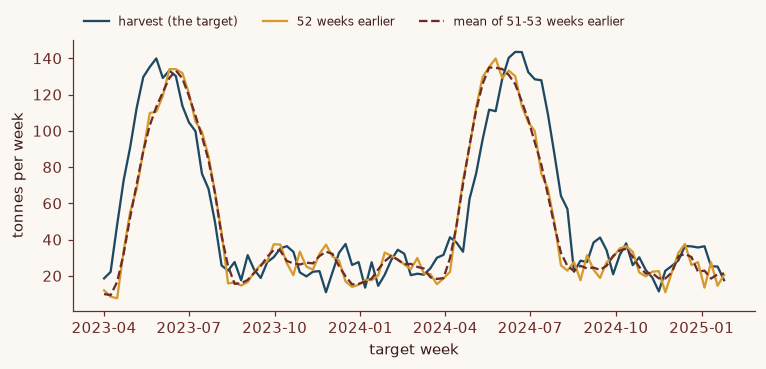

In [4]:
def seasonal_features(panel):
    g = panel.groupby("farm")["y"]
    return pd.DataFrame({
        "season_52": g.shift(52 - H),  # y[t+h-52]
        "season_51_53": g.transform(lambda s: s.shift(51 - H).rolling(3).mean()),  # y[t+h-53 .. t+h-51]
    })


print("ISO week of 2020-12-31:", pd.Timestamp("2020-12-31").isocalendar().week)

d = pd.concat([panel, target.rename("target"), seasonal_features(panel)], axis=1)
d = d[(d.farm == "D") & (d.week >= "2023-03-01") & (d.week < "2025-01-01")]
colours = fallcolor.palette.discrete("default")
labels = {"target": "harvest (the target)", "season_52": "52 weeks earlier", "season_51_53": "mean of 51-53 weeks earlier"}
fig, ax = plt.subplots(figsize=(8, 3.2))
for (col, label), c, ls in zip(labels.items(), colours, ["-", "-", "--"]):
    ax.plot(d.week + pd.Timedelta(weeks=H), d[col], color=c, ls=ls, label=label)
ax.set(xlabel="target week", ylabel="tonnes per week")
ax.legend(fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
plt.show()

<strong>Figure 1 | The seasonal lag is only as good as last year's timing.</strong> Farm D's synthetic harvest by target week, with the value 52 weeks earlier and the 51–53-week mean. The 2023 season started $106 - 98 = 8$ days earlier than 2022's and leads its lag; 2024's started $110 - 98 = 12$ days later and trails.

No feature built from last year alone corrects that; comparing this year's values with last year's (`yoy`, below) can show a season running early.

## Windows, trends and ratios

Windows summarise the recent past in few columns. What keeps them causal is order: **shift by $d$ first, then roll.** `known()` already shifts, so every window ends at $y_{t-d}$. All are per farm:

- **Rolling mean** (4 weeks): current level, less noisy than one lag.
- **Rolling standard deviation, minimum, maximum** (8 weeks): volatility and range, for when the spread changes through the season.
- **Trend slope** (6 weeks): momentum on a season's edges; the least-squares slope in t/week per week.
- **Expanding mean**: the farm's long-run level, for panels whose series differ in size.
- **Exponentially weighted mean** (EWM): recency weighting, weights halving every 2 weeks back; faster than a long window, smoother than a short one.
- **Differences and ratios to a lag**: change rather than level, for models that cannot form it. `diff_1` is the newest weekly change; `yoy`, the latest 4-week mean over the same weeks a year earlier, says whether this season runs ahead of last; `season_x_yoy` scales the seasonal mean by it.

In [5]:
SLOPE = (np.arange(6) - 2.5) / ((np.arange(6) - 2.5) ** 2).sum()  # least-squares slope weights, n = 6


def window_features(panel):
    k = known(panel).groupby(panel["farm"])  # shift first, then roll
    f = pd.DataFrame({
        "mean_4": k.transform(lambda s: s.rolling(4).mean()),
        "std_8": k.transform(lambda s: s.rolling(8).std()),
        "min_8": k.transform(lambda s: s.rolling(8).min()),
        "max_8": k.transform(lambda s: s.rolling(8).max()),
        "slope_6": k.transform(lambda s: s.rolling(6).apply(lambda w: w @ SLOPE, raw=True)),
        "ewm_hl2": k.transform(lambda s: s.ewm(halflife=2).mean()),
        "expanding_mean": k.transform(lambda s: s.expanding().mean()),
    })
    a_year_ago = k.transform(lambda s: s.shift(52).rolling(4).mean())
    f["diff_1"] = k.diff()  # lag_5 - lag_6
    f["yoy"] = f["mean_4"] / a_year_ago
    f["season_x_yoy"] = seasonal_features(panel)["season_51_53"] * f["yoy"]
    return f

### Test every feature

The leakage module's test, for rows indexed by origin: at each origin $t$, hide every week after $t - d$, rebuild the features, and check the row for $t$ is unchanged. It runs here over all $364$ origins; when that is slow, use a random sample of origins plus each series' first weeks, where leaks across series sit. Two deliberate bugs join the honest features: a 4-week mean rolled without the shift, and the known value shifted without `groupby`.

In [6]:
def build(panel):
    return pd.concat([lag_features(panel), seasonal_features(panel), window_features(panel)], axis=1)


def leaky(panel):
    return pd.DataFrame({
        "mean_4, rolled without the shift": panel.groupby("farm")["y"].transform(lambda s: s.rolling(4).mean()),
        "lag_5, shifted without groupby": panel["y"].shift(D),
    })


def known_at_origin(make, panel, origins):
    """For each column: unchanged at every origin t when all weeks after t - d are hidden?"""
    full = make(panel)
    ok = pd.Series(True, index=full.columns)
    for t in origins:
        hidden = panel.assign(y=panel.y.where(panel.week <= t - pd.Timedelta(weeks=D)))
        row = panel.week == t
        ok &= np.isclose(make(hidden)[row], full[row], equal_nan=True).all(axis=0)
    return ok


checks = known_at_origin(lambda p: pd.concat([build(p), leaky(p)], axis=1), panel, panel.week.unique())
print(f"{checks.sum()} of {len(checks)} features known at every origin; failed:")
print(checks[~checks])
bled = panel.y.shift(D).fillna(-1) != known(panel).fillna(-1)
print("rows where the ungrouped lag differs:", bled.sum(), "of", len(panel))

16 of 18 features known at every origin; failed:
mean_4, rolled without the shift    False
lag_5, shifted without groupby      False
dtype: bool
rows where the ungrouped lag differs: 3 of 1456


The $16$ honest features pass, the centred seasonal window included. The unshifted mean fails because it contains $y_t$; with $d = 0$ it would be legal, so the shift to apply is the latency. The ungrouped lag is wrong on $3$ rows of $1{,}456$, the first week of farms B, C and D. No backtest score would show three rows; the test does.

## How many features

The autocorrelation function (ACF) at lag $k$ is the correlation between $y_t$ and $y_{t-k}$. The partial autocorrelation function (PACF) measures the relationship between $y_t$ and $y_{t-k}$ after removing the effects of lags $1$ to $k-1$[^1]. Spikes outside $\pm 1.96/\sqrt{n}$, roughly the $95\%$ band for independent values of a series of length $n$, are candidates.

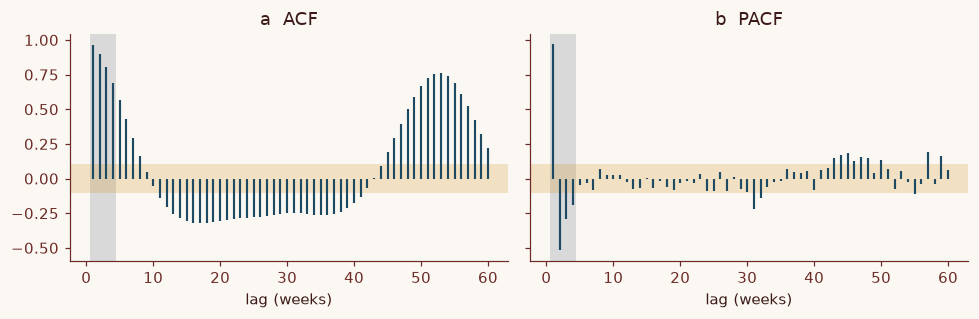

ACF at lags 1, 5, 52: 0.96, 0.56, 0.75; band +/-0.10
PACF outside the band at lags [1, 2, 3, 4, 31, 32, 43, 44, 45, 46, 47, 48, 50, 55, 57, 59]


In [7]:
y_d = panel.loc[panel.farm == "D", "y"].to_numpy()
r, q = acf(y_d, nlags=60), pacf(y_d, nlags=60)
band = 1.96 / np.sqrt(len(y_d))
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, vals, name in zip(axes, [r, q], ["a  ACF", "b  PACF"]):
    ax.axvspan(0.5, H + D - 0.5, color="0.85", lw=0)
    ax.axhspan(-band, band, color=colours[1], alpha=0.25, lw=0)
    ax.vlines(range(1, 61), 0, vals[1:], color=colours[0], lw=1.4)
    ax.set(title=name, xlabel="lag (weeks)")
fig.tight_layout()
plt.show()
print(f"ACF at lags 1, 5, 52: {r[1]:.2f}, {r[5]:.2f}, {r[52]:.2f}; band +/-{band:.2f}")
print("PACF outside the band at lags", np.flatnonzero(np.abs(q) > band)[1:].tolist())

<strong>Figure 2 | The short-term memory sits in lags the model cannot use.</strong> <strong>a</strong>, ACF and <strong>b</strong>, PACF of farm D's synthetic harvest, $n = 364$. Grey: lags shorter than $h + d = 5$. Shaded: $\pm 1.96/\sqrt{n}$.

The ACF falls from $0.96$ at lag 1 to $0.56$ at lag 5, the first usable lag, and returns to $0.75$ at lag 52; the PACF is outside the band at lags 1 to 4, then at scattered longer lags. In practice: start from lags $h + d$ to $h + d + 3$ plus the seasonal lag, and do not chase scattered PACF spikes.

A backtest decides the rest. This one follows [Backtesting properly](../backtesting/backtesting_properly.ipynb), simplified to one fit with the final year as test set, over 20 simulated panels with seven years of history and with four. The model is ridge regression on standardised features, a simple model chosen to isolate what each feature group adds as groups are added one at a time. Every group is scored on rows where all 60 lags exist, so the smaller sets train on fewer rows than they could. The season-start spread and history lengths were chosen after a short exploration (spreads of 10 to 20 days, four or seven years); the direction of the results held across the settings tried.

In [8]:
windows = ["mean_4", "std_8", "min_8", "max_8", "slope_6", "ewm_hl2", "expanding_mean"]
GROUPS = {"last known": ["lag_5"], "+ recent lags": ["lag_6", "lag_7", "lag_8"],
          "+ seasonal lags": ["season_52", "season_51_53"], "+ windows": windows,
          "+ differences and ratios": ["diff_1", "yoy", "season_x_yoy"],
          "+ lags 9 to 60": [f"lag_{k}" for k in range(9, 61)]}


def backtest(panel):
    X = pd.concat([build(panel), lag_features(panel, n=56).iloc[:, 4:]], axis=1)  # adds lags 9 to 60
    y = panel.groupby("farm")["y"].shift(-H)
    usable = X.notna().all(axis=1) & y.notna()
    first_test = panel.week.max() - pd.Timedelta(weeks=51)
    train = usable & (panel.week <= first_test - pd.Timedelta(weeks=H + D))  # targets known by then
    test = usable & (panel.week >= first_test)
    mae = {"naive": mean_absolute_error(y[test], X.loc[test, "lag_5"]),
           "seasonal naive": mean_absolute_error(y[test], X.loc[test, "season_52"])}
    cols = []
    for name, added in GROUPS.items():
        cols += added
        model = make_pipeline(StandardScaler(), Ridge()).fit(X.loc[train, cols], y[train])
        mae[name] = mean_absolute_error(y[test], model.predict(X.loc[test, cols]))
    return pd.Series(mae)


summary = {}
for years in [7, 4]:
    runs = pd.DataFrame({s: backtest(simulate(s, n_years=years)[0]) for s in range(20)}).T
    summary[f"{years} yr: ratio"] = runs.div(runs["seasonal naive"], axis=0).mean()
    summary[f"{years} yr: better"] = (runs.diff(axis=1) < 0).sum()[list(GROUPS)[1:]]
pd.DataFrame(summary).reindex(runs.columns).round(2).astype({c: "Int64" for c in summary if "better" in c})

,7 yr: ratio,7 yr: better,4 yr: ratio,4 yr: better
naive,1.89,<NA>,1.94,<NA>
seasonal naive,1.00,<NA>,1.00,<NA>
last known,1.82,<NA>,1.88,<NA>
+ recent lags,1.57,20,1.62,20
+ seasonal lags,0.99,19,1.04,20
+ windows,0.92,18,1.00,19
+ differences and ratios,0.93,6,1.04,6
+ lags 9 to 60,0.88,14,1.11,9


*Ratio*: mean over panels of the model's mean absolute error divided by seasonal naive's. *Better*: panels in which the group lowered the error of the row above.

With seven years, the newest usable value alone has $1.82$ times seasonal naive's error; seasonal lags bring it to $0.99$ and trailing windows to $0.92$, better in $18$ of $20$ panels. Differences and ratios add nothing ($0.93$, better in $6$): a linear model already forms `diff_1` as `lag_5 - lag_6`, and the ratios are noisy. Tree models handle ratios and interactions differently; rerun the ablation with your own model.

Lags 9 to 60 helped with seven years ($0.88$, better in $14$). With four they gave no reliable gain: slightly worse on average ($1.11$ against $1.04$), better in only $9$ of $20$. That is two settings, not a rule; there is no general rows-per-feature threshold here, so run the same ablation on your own backtest. A 60-week lag also discards more than a year of every series.

A workable default is the last few usable lags, the seasonal lag and a few trailing windows; add more only when a backtest on the history you actually have says so.

## Key takeaways

- One row per series and origin: target $y_{t+h}$, features known at $t$. Name lags by distance from the target; use none below $h + d$.
- Shift by $d$ within each series, then roll, expand or weight.
- Use `shift(52)` for the seasonal lag, not an ISO-week join. Neither fixes a season that starts late.
- Run the hide-the-future test on every feature. It caught an unshifted window and a three-row bleed between farms.
- ACF and PACF suggest lags; an incremental ablation in the backtest decides. Here 52 more lags helped with seven years of history and gave no reliable gain with four.

## References

[^1]: Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice* 3rd edn (OTexts, 2021).

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/forecast/1_feature_engineering.html"><span>Previous</span>Feature engineering with feature_engine</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/baselines-first.html"><span>Next</span>Baselines first</a></div>
<!-- CURRICULUM_FOOTER_END -->